In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Windows 设置中文
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print("✅ 所有库导入成功！")


✅ 所有库导入成功！


In [5]:
df = pd.read_csv("UserBehavior.csv")
df.columns = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']
# 随机采样10万行，降低内存压力
df = df.sample(n=100000, random_state=42) # random_state固定随机种子，每次采样一样，可复现
df.head()


,user_id,item_id,category_id,behavior_type,timestamp
43314727,237858,1481482,2733371,pv,1512225772
88035904,44200,3916487,4135836,pv,1511931558
38200464,920479,1955086,2355072,pv,1512313496
83578910,239462,2698818,154040,pv,1511783539
78996463,947273,3511372,1029459,pv,1512273859


In [6]:
# 导入时间库
from datetime import datetime

# 把时间戳转为datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')

# 提取日期、小时
df['date'] = df['datetime'].dt.date
df['hour'] = df['datetime'].dt.hour

# 查看时间范围
print("最小时间：", df['datetime'].min())
print("最大时间：", df['datetime'].max())


最小时间： 1970-01-01 02:11:04
最大时间： 2017-12-03 15:59:48


In [7]:
# 设定合法时间区间
start_time = datetime(2017,11,25)
end_time = datetime(2017,12,4)

# 过滤
df = df[(df['datetime'] >= start_time) & (df['datetime'] < end_time)]

# 重置索引
df = df.reset_index(drop=True)

print("过滤后数据行数：", len(df))


过滤后数据行数： 98735


In [8]:
print(df['behavior_type'].value_counts())


pv      88462
cart     5457
fav      2838
buy      1978
Name: behavior_type, dtype: int64


In [9]:
print(df.isnull().sum())


user_id          0
item_id          0
category_id      0
behavior_type    0
timestamp        0
datetime         0
date             0
hour             0
dtype: int64


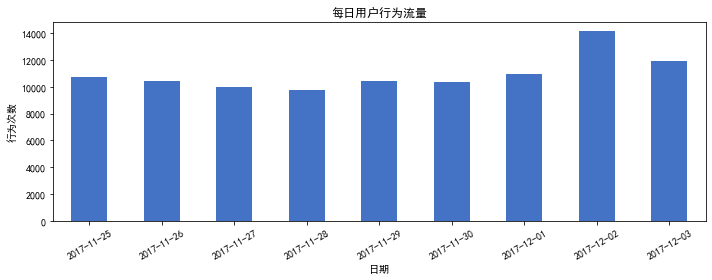

In [10]:
# 按日期分组，统计当天的行为条数
daily_flow = df.groupby('date').size()

# 画图
plt.figure(figsize=(10,4))
daily_flow.plot(kind='bar', color='#4472C4')
plt.title('每日用户行为流量')
plt.xlabel('日期')
plt.ylabel('行为次数')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


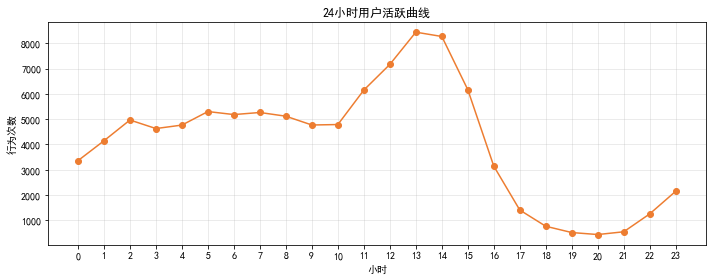

In [11]:
# 24小时用户活跃曲线
hour_flow = df.groupby('hour').size()
plt.figure(figsize=(10,4))
hour_flow.plot(kind='line', marker='o', color='#ED7D31')
plt.title('24小时用户活跃曲线')
plt.xlabel('小时')
plt.ylabel('行为次数')
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [12]:
# 1. 每个用户，标记他有没有发生过各类行为
user_behavior = df.groupby('user_id')['behavior_type'].agg(lambda x: set(x)).reset_index()

# 定义标记：是否浏览、是否加购、是否收藏、是否购买
user_behavior['is_pv'] = user_behavior['behavior_type'].apply(lambda x: 'pv' in x)
user_behavior['is_cart'] = user_behavior['behavior_type'].apply(lambda x: 'cart' in x)
user_behavior['is_fav'] = user_behavior['behavior_type'].apply(lambda x: 'fav' in x)
user_behavior['is_buy'] = user_behavior['behavior_type'].apply(lambda x: 'buy' in x)

# 统计各环节UV
pv_uv = user_behavior['is_pv'].sum()
cart_uv = user_behavior['is_cart'].sum()
fav_uv = user_behavior['is_fav'].sum()
buy_uv = user_behavior['is_buy'].sum()

print(f"浏览UV：{pv_uv}")
print(f"加购UV：{cart_uv}")
print(f"收藏UV：{fav_uv}")
print(f"下单UV：{buy_uv}")

# 计算转化率
print("-"*30)
print(f"浏览→加购转化率：{cart_uv/pv_uv:.2%}")
print(f"浏览→收藏转化率：{fav_uv/pv_uv:.2%}")
print(f"浏览→下单转化率：{buy_uv/pv_uv:.2%}")
print(f"加购/收藏→下单转化率：{buy_uv/(cart_uv+fav_uv):.2%}")


浏览UV：82060
加购UV：5418
收藏UV：2805
下单UV：1969
------------------------------
浏览→加购转化率：6.60%
浏览→收藏转化率：3.42%
浏览→下单转化率：2.40%
加购/收藏→下单转化率：23.95%


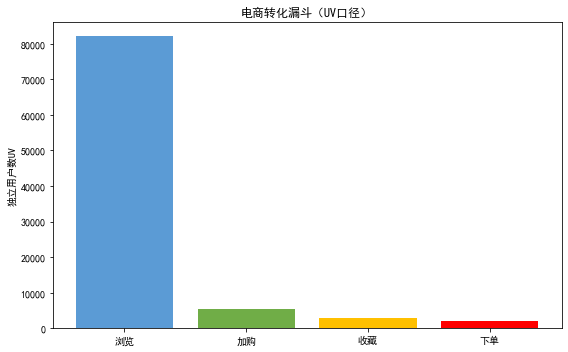

In [13]:
funnel_name = ['浏览', '加购', '收藏', '下单']
funnel_uv = [pv_uv, cart_uv, fav_uv, buy_uv]

plt.figure(figsize=(8,5))
plt.bar(funnel_name, funnel_uv, color=['#5B9BD5','#70AD47','#FFC000','#FF0000'])
plt.title('电商转化漏斗（UV口径）')
plt.ylabel('独立用户数UV')
plt.tight_layout()
plt.show()


低价值沉睡用户    1045
潜力新客        915
流失老客          6
高价值用户         3
Name: user_type, dtype: int64


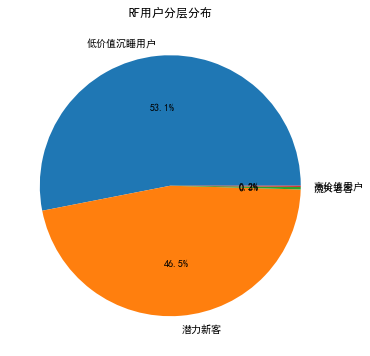

In [15]:
# 只保留购买行为的数据
buy_df = df[df['behavior_type'] == 'buy'].copy()

# 统计每个用户：最后购买时间、购买次数
user_rf = buy_df.groupby('user_id').agg(
    last_buy_time=('datetime', 'max'),
    buy_freq=('datetime', 'count')
).reset_index()

# 取整个数据集的最后一天作为参考基准日
max_date = df['datetime'].max()
# 计算R：距离最后一次下单的天数
user_rf['R_days'] = (max_date - user_rf['last_buy_time']).dt.days

# ----------------------改用cut固定阈值，避开qcut分箱失败问题----------------------
# R：距离购买天数，<=3天 =近期购买（得分2），>3天=很久没买（得分1）
user_rf['R_score'] = pd.cut(user_rf['R_days'], bins=[-1,3,999], labels=[2,1])
# F：购买次数，>=2次 =复购用户（得分2），=1次=只买过1次（得分1）
user_rf['F_score'] = pd.cut(user_rf['buy_freq'], bins=[0,1,999], labels=[1,2])

# 合并打分，用户分层
def rf_label(row):
    if row['R_score'] == 2 and row['F_score'] ==2:
        return '高价值用户'
    elif row['R_score'] ==2 and row['F_score'] ==1:
        return '潜力新客'
    elif row['R_score'] ==1 and row['F_score'] ==2:
        return '流失老客'
    else:
        return '低价值沉睡用户'

user_rf['user_type'] = user_rf.apply(rf_label, axis=1)

# 统计分层数量
print(user_rf['user_type'].value_counts())

# 画分层饼图
plt.figure(figsize=(6,6))
user_rf['user_type'].value_counts().plot(kind='pie', autopct='%.1f%%')
plt.title('RF用户分层分布')
plt.ylabel('')
plt.show()


In [16]:
# 统计每个类目下浏览量pv、下单量buy
cat_pv = df[df['behavior_type']=='pv'].groupby('category_id').size()
cat_buy = df[df['behavior_type']=='buy'].groupby('category_id').size()

# 合并成一张表
cat_conv = pd.DataFrame({'pv': cat_pv, 'buy': cat_buy}).fillna(0)
# 计算类目转化率：下单数 / 浏览数
cat_conv['conv_rate'] = cat_conv['buy'] / cat_conv['pv']

# 浏览量Top10类目
print("浏览量Top10类目：")
print(cat_conv['pv'].sort_values(ascending=False).head(10))
print("-"*40)
# 转化率Top10类目（只看有足够浏览的类目，避免偶然高转化）
valid_cat = cat_conv[cat_conv['pv'] >= 50]
print("有效类目转化率Top10：")
print(valid_cat['conv_rate'].sort_values(ascending=False).head(10))


浏览量Top10类目：
category_id
4756105    4440.0
2355072    3120.0
4145813    3049.0
3607361    2949.0
982926     2819.0
2520377    2079.0
1320293    1843.0
4801426    1821.0
2465336    1524.0
3002561    1400.0
Name: pv, dtype: float64
----------------------------------------
有效类目转化率Top10：
category_id
366112     0.113208
4159072    0.106145
3231625    0.100000
1548278    0.092593
1449177    0.092308
4640311    0.090909
800581     0.088235
2304296    0.078431
2440115    0.074380
2495340    0.068966
Name: conv_rate, dtype: float64


In [ ]:
# 项目总结&业务建议
1. 用户行为：绝大部分用户仅浏览，从浏览到加购是最大流失环节；用户活跃高峰集中在下午14-15点。
2. 转化现状：大盘浏览→下单转化率仅2.4%，但有加购/收藏行为的用户转化可以达到23.95%，建议针对【加购未下单】用户做消息召回、优惠券推送。
3. 用户结构：样本中复购用户极少，大量为沉睡低价值用户，少量潜力新客；运营策略区分：潜力新客发放复购券唤醒二次购买，沉睡用户做定向召回活动。
4. 类目策略：头部类目流量大但转化一般；部分小众类目转化率很高，可以适当增加曝光、流量倾斜，提升整体GMV。


===== 一次性用户、复购用户行为均值对比 =====
               pv_cnt  cart_cnt  fav_cnt
user_buy_type                           
一次性下单用户          0.11      0.01      0.0
复购用户             0.00      0.00      0.0


<Figure size 576x360 with 0 Axes>

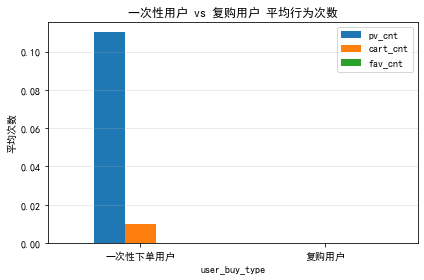

In [17]:
# ===== 一次性下单用户 VS 复购用户 行为对比（修复版）
# 思路：先统计每个用户全部行为：浏览次数、加购次数、收藏次数、下单次数
user_all_act = df.groupby("user_id").agg(
    pv_cnt=("behavior_type", lambda x: (x=="pv").sum()),
    cart_cnt=("behavior_type", lambda x: (x=="cart").sum()),
    fav_cnt=("behavior_type", lambda x: (x=="fav").sum()),
    buy_cnt=("behavior_type", lambda x: (x=="buy").sum())
).reset_index()

# 给用户打上标签：一次性用户 / 复购用户
def buy_tag(row):
    if row["buy_cnt"] >= 2:
        return "复购用户"
    elif row["buy_cnt"] == 1:
        return "一次性下单用户"
    else:
        return "未下单用户"

user_all_act["user_buy_type"] = user_all_act.apply(buy_tag, axis=1)

# 筛选出有下单的用户，排除纯浏览未下单的
buy_user_df = user_all_act[user_all_act["user_buy_type"].isin(["一次性下单用户","复购用户"])]

# 分组求均值：平均浏览、平均加购、平均收藏
res = buy_user_df.groupby("user_buy_type")[["pv_cnt","cart_cnt","fav_cnt"]].mean().round(2)

print("===== 一次性用户、复购用户行为均值对比 =====")
print(res)

# 画对比柱状图
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
res.plot(kind="bar")
plt.title("一次性用户 vs 复购用户 平均行为次数")
plt.ylabel("平均次数")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
> 备注：采样样本内复购用户仅3人，且样本中无对应的浏览、加购、收藏前置行为记录，因此均值为0，该结论仅代表当前采样子集，不代表全量数据集规律。
